## image source : https://universe.roboflow.com/tunis-business-school-t3rrg/ui-detector-eulxp

In [1]:
from ultralytics import YOLO

In [7]:
model = YOLO("../models/yolov8_ui_model.pt")
model.predict("../resources/input/test.png", save=True)


image 1/1 /Users/tarunkashyap/Desktop/annotate/notebooks/../resources/input/test.png: 480x640 22 buttons, 4 fields, 2 headings, 11 images, 2 links, 26 texts, 126.7ms
Speed: 3.0ms preprocess, 126.7ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)
Results saved to runs/detect/predict
image 1/1 /Users/tarunkashyap/Desktop/annotate/notebooks/../resources/input/test.png: 480x640 22 buttons, 4 fields, 2 headings, 11 images, 2 links, 26 texts, 126.7ms
Speed: 3.0ms preprocess, 126.7ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)
Results saved to runs/detect/predict


[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 keypoints: None
 masks: None
 names: {0: 'button', 1: 'field', 2: 'heading', 3: 'iframe', 4: 'image', 5: 'label', 6: 'link', 7: 'text'}
 obb: None
 orig_img: array([[[  0,   0,   0],
         [  0,   0,   0],
         [  0,   0,   0],
         ...,
         [  0,   0,   0],
         [ 46,  46,  46],
         [ 46,  46,  46]],
 
        [[ 31,  29,  21],
         [ 31,  29,  21],
         [ 31,  30,  21],
         ...,
         [ 42,  37,  23],
         [ 81,  75,  65],
         [ 80,  76,  65]],
 
        [[ 41,  40,  28],
         [ 40,  40,  28],
         [ 40,  40,  28],
         ...,
         [ 57,  48,  31],
         [ 93,  86,  72],
         [ 93,  85,  71]],
 
        ...,
 
        [[ 15,  15,  14],
         [112, 112, 111],
         [227, 227, 227],
         ...,
         [ 27,  24,  22],
         [ 26,  23,  22],
         [ 27,  24,  22]],
 
        [[ 18,  18,  18],


image 1/1 /Users/tarunkashyap/Desktop/annotate/test.png: 480x640 18 buttons, 3 fields, 7 headings, 20 images, 33 texts, 126.2ms
Speed: 3.4ms preprocess, 126.2ms inference, 5.7ms postprocess per image at shape (1, 3, 480, 640)


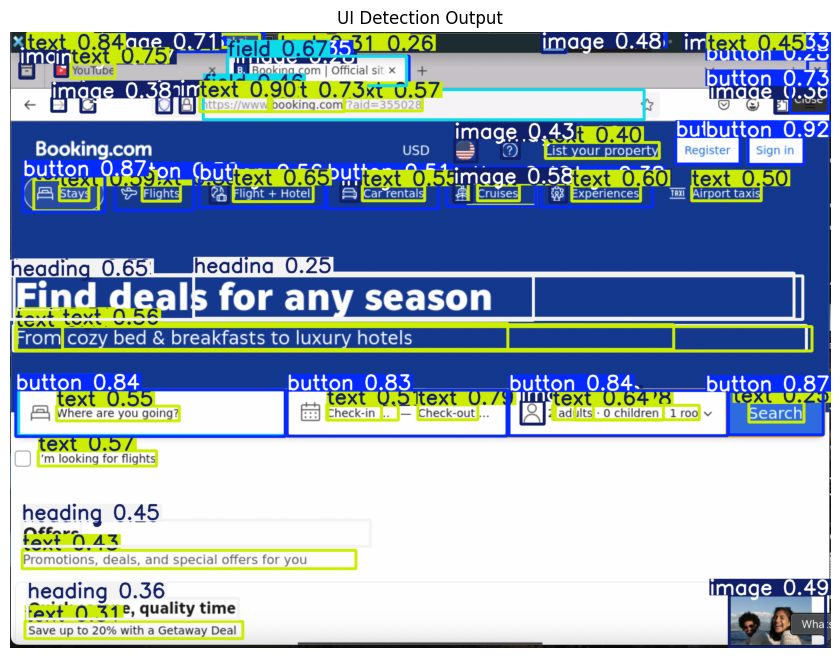

In [2]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

# Load the trained model
model = YOLO("yolov8_ui_model.pt")

# Predict on a local screenshot
results = model.predict(source="./test.png", save=False)
res = results[0]

# Visualize predictions
img = res.plot()
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("UI Detection Output")
plt.show()


image 1/1 /Users/tarunkashyap/Desktop/annotate/test.png: 480x640 18 buttons, 3 fields, 7 headings, 20 images, 33 texts, 118.5ms
Speed: 2.8ms preprocess, 118.5ms inference, 0.4ms postprocess per image at shape (1, 3, 480, 640)


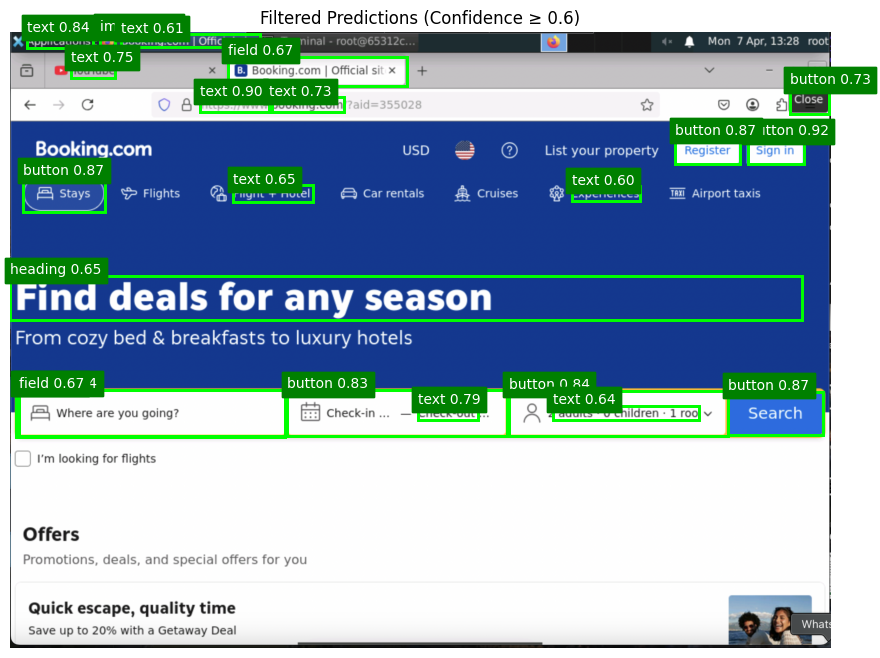

In [4]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2

# Load model and run prediction
model = YOLO("yolov8_ui_model.pt")
results = model.predict("test.png", save=False)
res = results[0]

# Load original image (for plotting)
image = cv2.imread("test.png")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Create plot
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)

# Draw only boxes with conf >= 0.6
for box in res.boxes:
    conf = float(box.conf[0])
    if conf < 0.6:
        continue

    cls_id = int(box.cls[0])
    label = res.names[cls_id]
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()  # ✅ FIXED

    width, height = x2 - x1, y2 - y1
    rect = patches.Rectangle((x1, y1), width, height,
                             linewidth=2, edgecolor='lime', facecolor='none')
    ax.add_patch(rect)

    ax.text(x1, y1 - 5, f'{label} {conf:.2f}',
            color='white', fontsize=10, backgroundcolor='green')

    ax.add_patch(rect)

    # Add label
    ax.text(x1, y1 - 5, f'{label} {conf:.2f}',
            color='white', fontsize=10, backgroundcolor='green')

plt.axis('off')
plt.title("Filtered Predictions (Confidence ≥ 0.6)")
plt.show()

In [ ]:
import os
from pathlib import Path
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

# Paths
input_dir = Path("./resources/input")
output_dir = Path("./resources/output")
output_dir.mkdir(exist_ok=True)

# Load model
model = YOLO("yolov8_ui_model.pt")

# Process each image in input
for img_path in input_dir.glob("*.png"):
    print(f"Processing {img_path.name}...")
    
    # Predict
    results = model.predict(source=str(img_path), save=False)
    res = results[0]
    
    # Visualize and save
    img = res.plot()
    output_path = output_dir / f"annotated_{img_path.name}"
    cv2.imwrite(str(output_path), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
    
    print(f"Saved annotated image to {output_path}")

print("Batch processing complete!")

In [ ]:
from openai import OpenAI
from PIL import Image
import io
import base64
import os
from pathlib import Path

def prepare_image(path):
    with Image.open(path) as img:
        img = img.convert("RGB")
        buffer = io.BytesIO()
        img.save(buffer, format="JPEG", quality=70)
        return base64.b64encode(buffer.getvalue()).decode()

# Load API key from .env
import os
api_key = os.getenv("OPENAI_API_KEY")
if not api_key:
    print("OPENAI_API_KEY not found in environment.")
else:
    client = OpenAI(api_key=api_key)

    # Process images in input
    input_dir = Path("./resources/input")
    for img_path in input_dir.glob("*.png"):
        print(f"Analyzing {img_path.name} with VLM...")
        
        base64_image = prepare_image(img_path)
        
        completion = client.chat.completions.create(
            model="gpt-4o-mini",
            messages=[
                {
                    "role": "user",
                    "content": [
                        {
                            "type": "text",
                            "text": "Describe the UI elements in this image and suggest possible actions."
                        },
                        {
                            "type": "image_url",
                            "image_url": {
                                "url": f"data:image/jpeg;base64,{base64_image}",
                            }
                        }
                    ]
                }
            ]
        )
        
        print(f"Description for {img_path.name}: {completion.choices[0].message.content}")
        print("-" * 50)